In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

#### Loading of the dataset

In [2]:
train = pd.read_csv(
    "../data/raw/train.csv",
    parse_dates=["date"]
)

stores = pd.read_csv(
    "../data/raw/stores.csv"
)

oil = pd.read_csv(
    "../data/raw/oil.csv",
    parse_dates=["date"]
)

holidays = pd.read_csv(
    "../data/raw/holidays_events.csv",
    parse_dates=["date"]
)

transactions = pd.read_csv(
    "../data/raw/transactions.csv",
    parse_dates=["date"]
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [42]:
train["week"] = train["date"].dt.isocalendar().week.astype(int)

In [43]:
train.head()

,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week,week,quarter,is_weekend,promotion_status
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1,Tuesday,1,1,0,No Promotion
1,1,2013-01-01,1,BABY CARE,0.0,0,2013,1,1,Tuesday,1,1,0,No Promotion
2,2,2013-01-01,1,BEAUTY,0.0,0,2013,1,1,Tuesday,1,1,0,No Promotion
3,3,2013-01-01,1,BEVERAGES,0.0,0,2013,1,1,Tuesday,1,1,0,No Promotion
4,4,2013-01-01,1,BOOKS,0.0,0,2013,1,1,Tuesday,1,1,0,No Promotion


#### Prepare date features

In [3]:
train["year"] = train["date"].dt.year

train["month"] = train["date"].dt.month

train["day"] = train["date"].dt.day

train["day_of_week"] = train["date"].dt.day_name()

train["week"] = train["date"].dt.isocalendar().week.astype(int)

train["quarter"] = train["date"].dt.quarter

train["is_weekend"] = (
    train["date"].dt.dayofweek >= 5
).astype(int)

#### Overall sales performance analysis

#### Calculate sales KPIs

In [4]:
total_sales = train["sales"].sum()

average_sales = train["sales"].mean()

median_sales = train["sales"].median()

maximum_sales = train["sales"].max()

minimum_sales = train["sales"].min()

print("Total Sales:", total_sales)

print("Average Sales:", average_sales)

print("Median Sales:", median_sales)

print("Maximum Sales:", maximum_sales)

print("Minimum Sales:", minimum_sales)

Total Sales: 1073644952.2030684
Average Sales: 357.77574911261877
Median Sales: 11.0
Maximum Sales: 124717.0
Minimum Sales: 0.0


### Sales Distribution

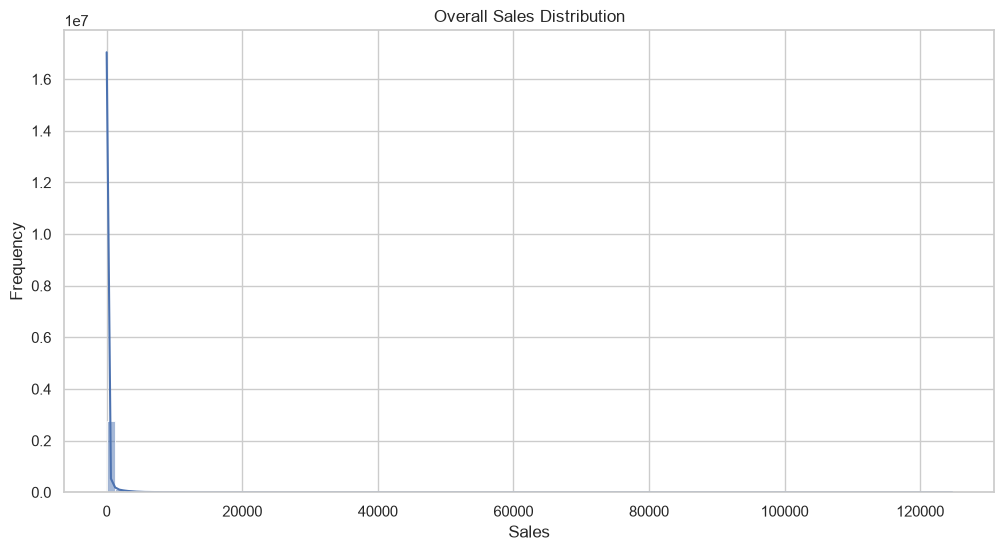

In [44]:
plt.figure(figsize=(12,6))

sns.histplot(
    train['sales'],
    bins=100,
    kde=True
)

plt.title("Overall Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()


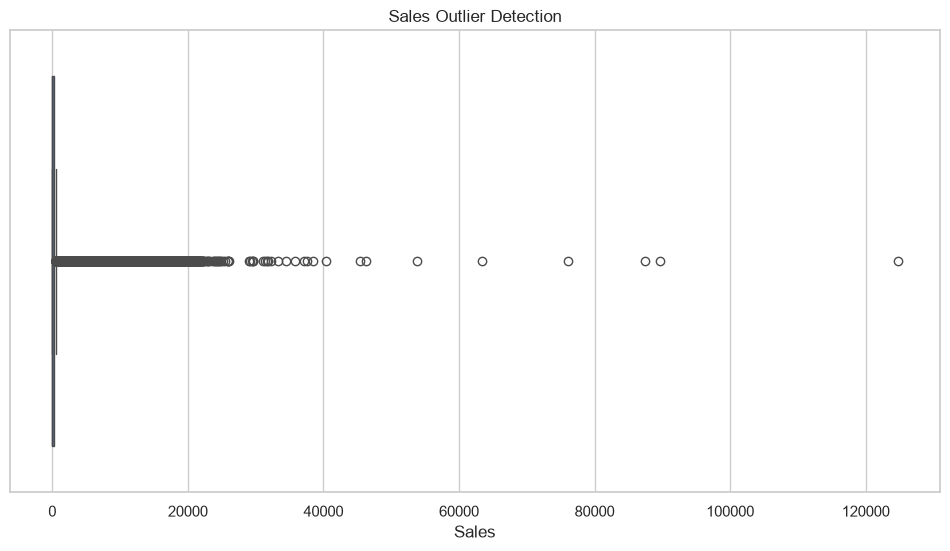

In [45]:
plt.figure(figsize=(12, 6))

sns.boxplot(x=train["sales"])

plt.title("Sales Outlier Detection")

plt.xlabel("Sales")

plt.show()

### Product category demand analysis


### Total sales by product family

In [7]:
product_sales = (
    train.groupby("family")["sales"]
    .sum()
    .sort_values(ascending=False)
)

product_sales.head(15)

family
GROCERY I           3.434627e+08
BEVERAGES           2.169545e+08
PRODUCE             1.227047e+08
CLEANING            9.752129e+07
DAIRY               6.448771e+07
BREAD/BAKERY        4.213395e+07
POULTRY             3.187600e+07
MEATS               3.108647e+07
PERSONAL CARE       2.459205e+07
DELI                2.411032e+07
HOME CARE           1.602274e+07
EGGS                1.558830e+07
FROZEN FOODS        1.407389e+07
PREPARED FOODS      8.799895e+06
LIQUOR,WINE,BEER    7.746640e+06
Name: sales, dtype: float64

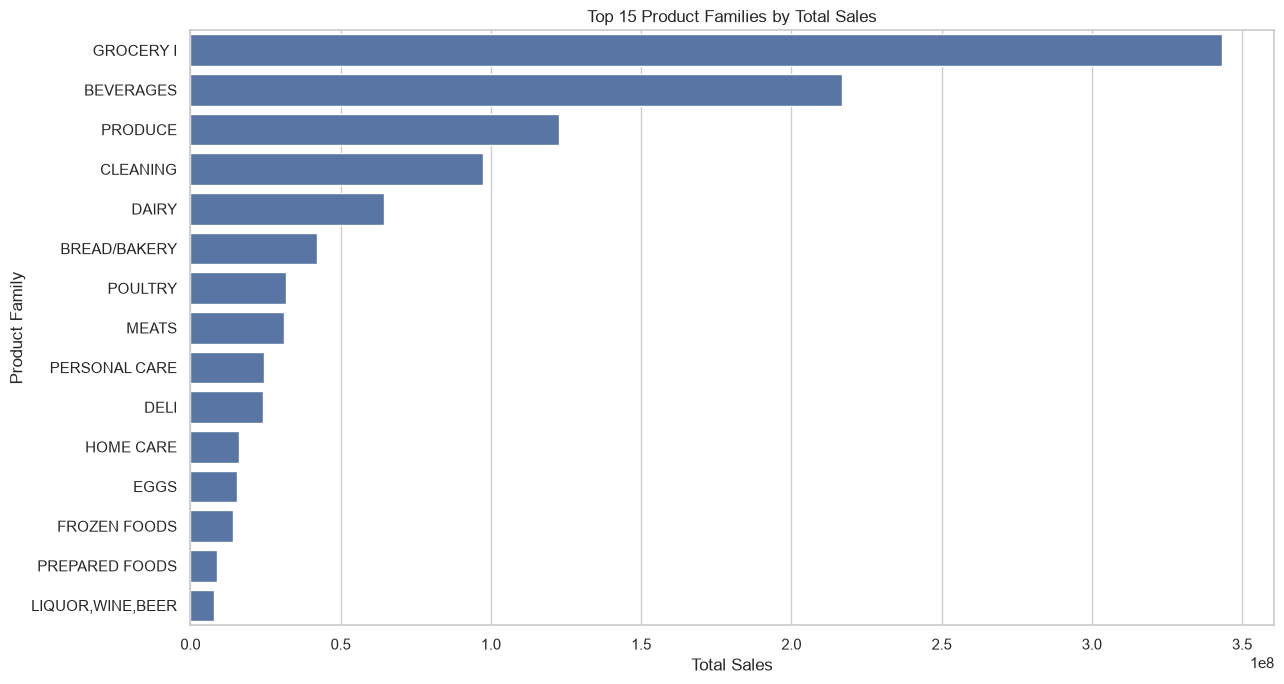

In [8]:
plt.figure(figsize=(13, 7))

sns.barplot(
    x=product_sales.head(15).values,
    y=product_sales.head(15).index
)

plt.title("Top 15 Product Families by Total Sales")

plt.xlabel("Total Sales")

plt.ylabel("Product Family")

plt.tight_layout()

plt.show()

In [9]:
product_contribution = (
    train.groupby("family")["sales"]
    .sum()
    .reset_index()
)

product_contribution["sales_percentage"] = (
    product_contribution["sales"] /
    product_contribution["sales"].sum()
) * 100

product_contribution = product_contribution.sort_values(
    by="sales_percentage",
    ascending=False
)

product_contribution.head(15)

,family,sales,sales_percentage
12,GROCERY I,3.434627e+08,31.990346
3,BEVERAGES,2.169545e+08,20.207284
30,PRODUCE,1.227047e+08,11.428795
7,CLEANING,9.752129e+07,9.083197
8,DAIRY,6.448771e+07,6.006428
5,BREAD/BAKERY,4.213395e+07,3.924384
28,POULTRY,3.187600e+07,2.968952
24,MEATS,3.108647e+07,2.895414
25,PERSONAL CARE,2.459205e+07,2.290520
9,DELI,2.411032e+07,2.245651


#### Store performance analysis

### Sales by store

In [10]:
store_sales = (
    train.groupby("store_nbr")["sales"]
    .sum()
    .sort_values(ascending=False)
)

store_sales.head(10)

store_nbr
44    6.208755e+07
45    5.449801e+07
47    5.094831e+07
3     5.048191e+07
49    4.342010e+07
46    4.189606e+07
48    3.593313e+07
51    3.291149e+07
8     3.049429e+07
50    2.865302e+07
Name: sales, dtype: float64

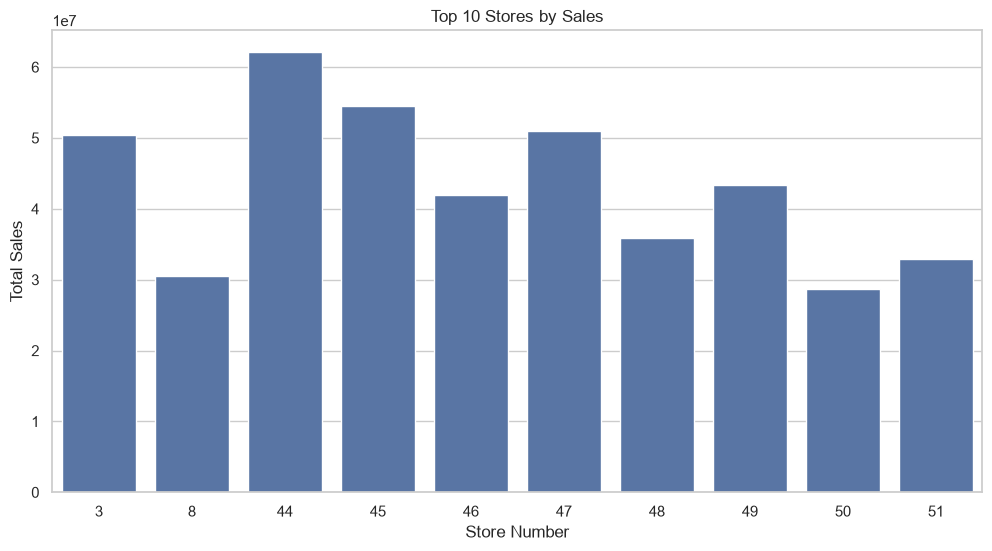

In [11]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=store_sales.head(10).index,
    y=store_sales.head(10).values
)

plt.title("Top 10 Stores by Sales")

plt.xlabel("Store Number")

plt.ylabel("Total Sales")

plt.show()

In [12]:
store_analysis = train.merge(
    stores,
    on="store_nbr",
    how="left"
)

store_analysis.head()

,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week,week,quarter,is_weekend,city,state,type,cluster
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1,Tuesday,1,1,0,Quito,Pichincha,D,13
1,1,2013-01-01,1,BABY CARE,0.0,0,2013,1,1,Tuesday,1,1,0,Quito,Pichincha,D,13
2,2,2013-01-01,1,BEAUTY,0.0,0,2013,1,1,Tuesday,1,1,0,Quito,Pichincha,D,13
3,3,2013-01-01,1,BEVERAGES,0.0,0,2013,1,1,Tuesday,1,1,0,Quito,Pichincha,D,13
4,4,2013-01-01,1,BOOKS,0.0,0,2013,1,1,Tuesday,1,1,0,Quito,Pichincha,D,13


In [13]:
store_type_sales = (
    store_analysis.groupby("type")["sales"]
    .sum()
    .sort_values(ascending=False)
)

store_type_sales

type
A    3.530438e+08
D    3.510833e+08
C    1.644347e+08
B    1.452606e+08
E    5.982244e+07
Name: sales, dtype: float64

In [14]:
city_sales = (
    store_analysis.groupby("city")["sales"]
    .sum()
    .sort_values(ascending=False)
)

city_sales.head(10)

city
Quito            5.567418e+08
Guayaquil        1.229673e+08
Cuenca           4.916860e+07
Ambato           4.030440e+07
Santo Domingo    3.583432e+07
Machala          3.338680e+07
Cayambe          2.832556e+07
Latacunga        2.118226e+07
Daule            1.918802e+07
Loja             1.886000e+07
Name: sales, dtype: float64

### Time-series demand analysis

#### Daily Sales

In [16]:
daily_sales = (
    train.groupby("date")["sales"]
    .sum()
    .reset_index()
)

daily_sales.head()

,date,sales
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229


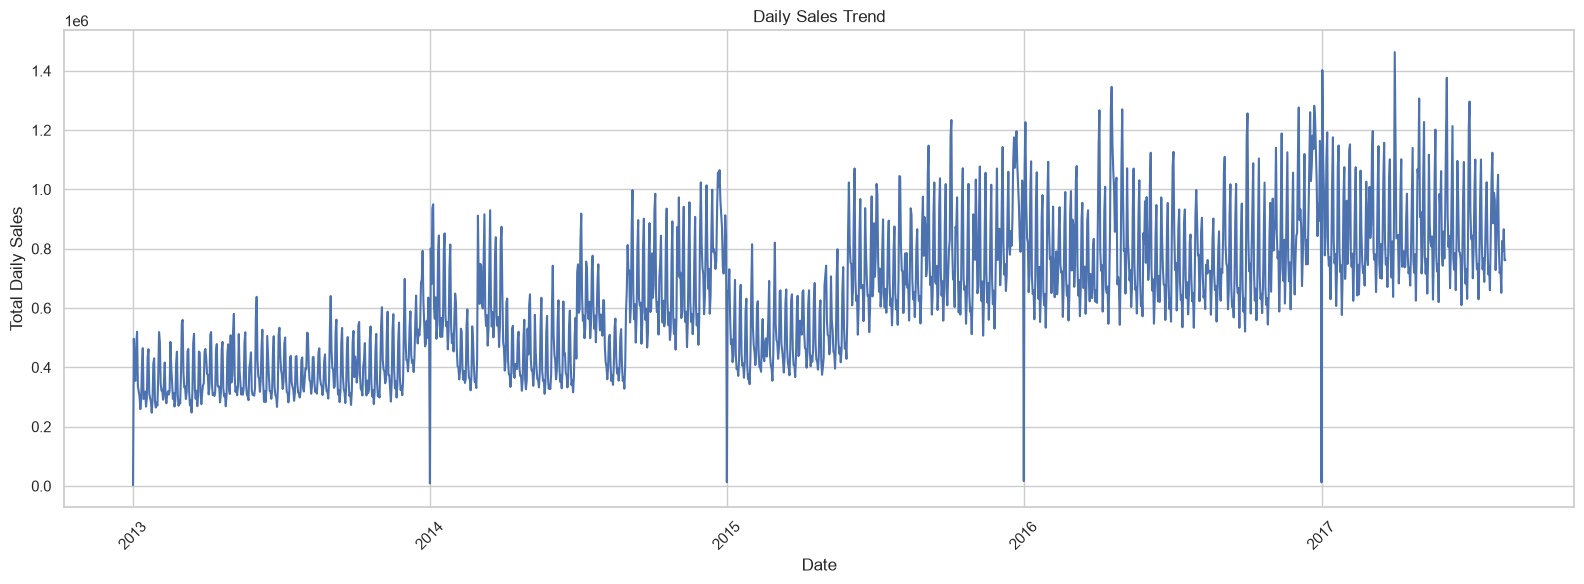

In [17]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_sales["date"],
    daily_sales["sales"]
)

plt.title("Daily Sales Trend")

plt.xlabel("Date")

plt.ylabel("Total Daily Sales")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

#### Weekly Sales

In [18]:
weekly_sales = (
    daily_sales.set_index("date")["sales"]
    .resample("W")
    .sum()
)

weekly_sales.head()

date
2013-01-06    2.211570e+06
2013-01-13    2.373618e+06
2013-01-20    2.368007e+06
2013-01-27    2.272165e+06
2013-02-03    2.476891e+06
Freq: W-SUN, Name: sales, dtype: float64

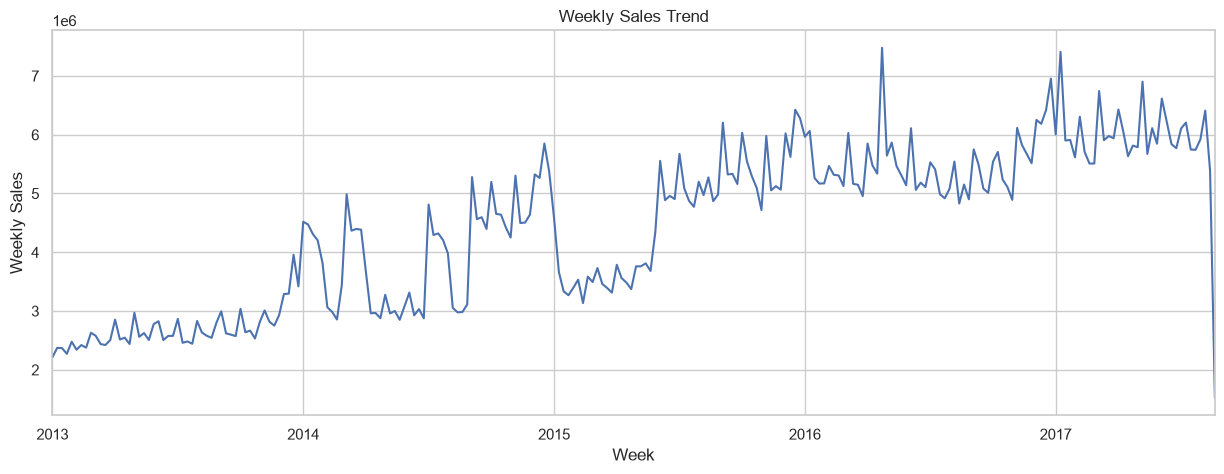

In [19]:
plt.figure(figsize=(15, 5))

weekly_sales.plot()

plt.title("Weekly Sales Trend")

plt.xlabel("Week")

plt.ylabel("Weekly Sales")

plt.show()

#### Monthly Sales

In [20]:
monthly_sales = (
    daily_sales.set_index("date")["sales"]
    .resample("MS")
    .sum()
)

monthly_sales.head()

date
2013-01-01    1.032762e+07
2013-02-01    9.658960e+06
2013-03-01    1.142850e+07
2013-04-01    1.099346e+07
2013-05-01    1.159770e+07
Freq: MS, Name: sales, dtype: float64

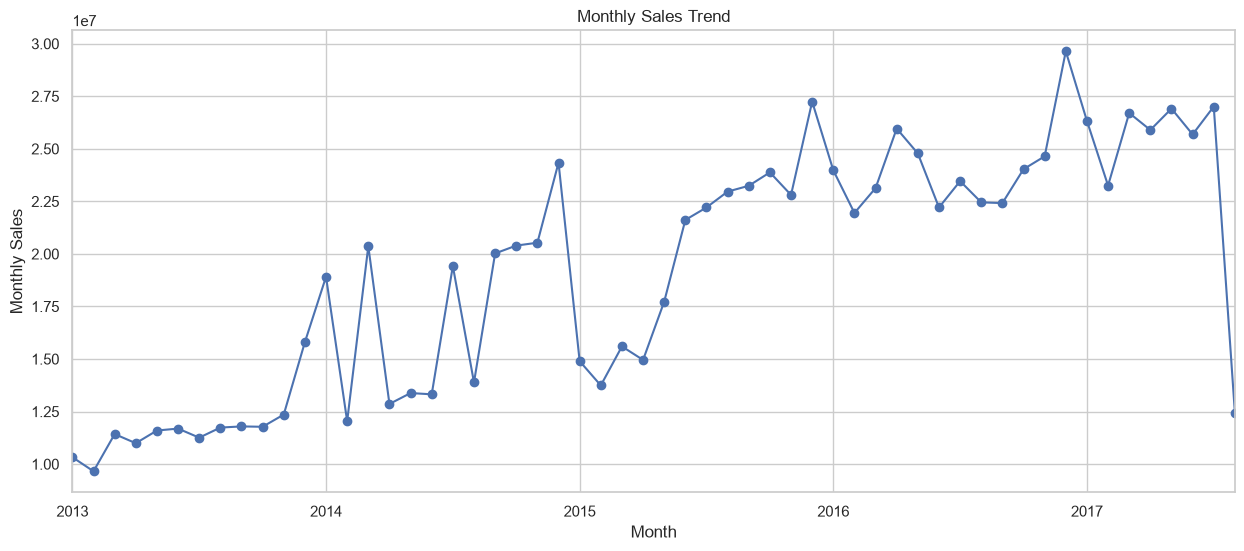

In [21]:
plt.figure(figsize=(15, 6))

monthly_sales.plot(
    marker="o"
)

plt.title("Monthly Sales Trend")

plt.xlabel("Month")

plt.ylabel("Monthly Sales")

plt.show()

In [22]:
weekday_sales = (
    train.groupby("day_of_week")["sales"]
    .mean()
)

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_sales = weekday_sales.reindex(weekday_order)

weekday_sales

day_of_week
Monday       346.544732
Tuesday      319.823843
Wednesday    332.909401
Thursday     283.540517
Friday       325.238138
Saturday     433.336472
Sunday       463.085366
Name: sales, dtype: float64

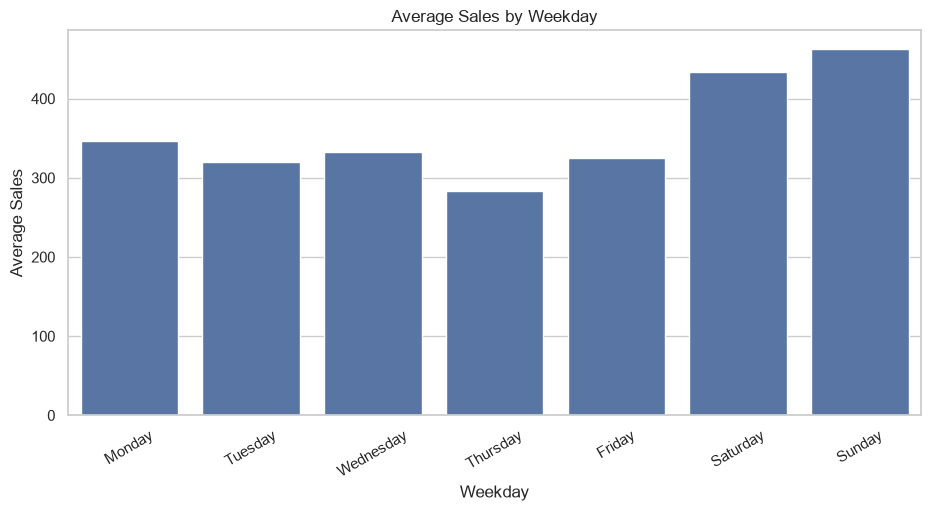

In [23]:
plt.figure(figsize=(11, 5))

sns.barplot(
    x=weekday_sales.index,
    y=weekday_sales.values
)

plt.title("Average Sales by Weekday")

plt.xlabel("Weekday")

plt.ylabel("Average Sales")

plt.xticks(rotation=30)

plt.show()

### Promotion impact analysis

In [24]:
train["promotion_status"] = np.where(
    train["onpromotion"] > 0,
    "Promotion",
    "No Promotion"
)


In [25]:
promotion_analysis = (
    train.groupby("promotion_status")["sales"]
    .agg(["mean", "median", "sum", "count"])
)

promotion_analysis

,mean,median,sum,count
promotion_status,,,,
No Promotion,158.246681,3.0,3.781398e+08,2389559
Promotion,1137.693730,373.0,6.955052e+08,611329


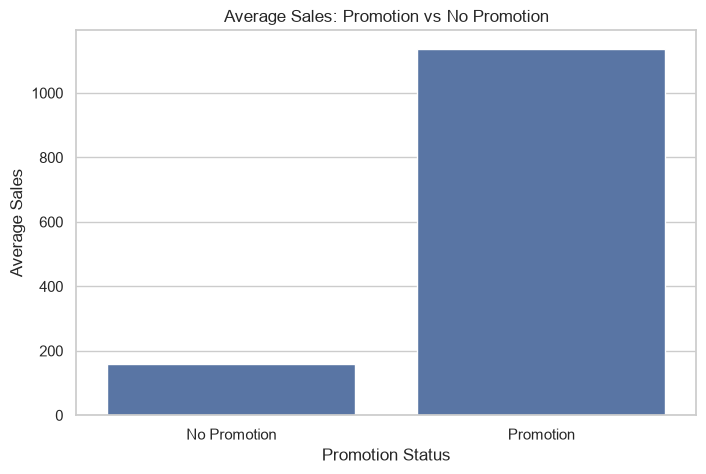

In [26]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=train,
    x="promotion_status",
    y="sales",
    errorbar=None
)

plt.title("Average Sales: Promotion vs No Promotion")

plt.xlabel("Promotion Status")

plt.ylabel("Average Sales")

plt.show()

#### Holiday demand analysis

In [27]:
holidays.head()

,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False


In [28]:
holiday_analysis = train.merge(
    holidays[["date", "type", "locale", "transferred"]],
    on="date",
    how="left"
)

holiday_analysis.head()

,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week,week,quarter,is_weekend,promotion_status,type,locale,transferred
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1,Tuesday,1,1,0,No Promotion,Holiday,National,False
1,1,2013-01-01,1,BABY CARE,0.0,0,2013,1,1,Tuesday,1,1,0,No Promotion,Holiday,National,False
2,2,2013-01-01,1,BEAUTY,0.0,0,2013,1,1,Tuesday,1,1,0,No Promotion,Holiday,National,False
3,3,2013-01-01,1,BEVERAGES,0.0,0,2013,1,1,Tuesday,1,1,0,No Promotion,Holiday,National,False
4,4,2013-01-01,1,BOOKS,0.0,0,2013,1,1,Tuesday,1,1,0,No Promotion,Holiday,National,False


In [29]:
holiday_analysis["is_holiday"] = (
    holiday_analysis["type"].notna()
).astype(int)

holiday_sales = (
    holiday_analysis.groupby("is_holiday")["sales"]
    .mean()
)

holiday_sales

is_holiday
0    352.159181
1    393.864762
Name: sales, dtype: float64

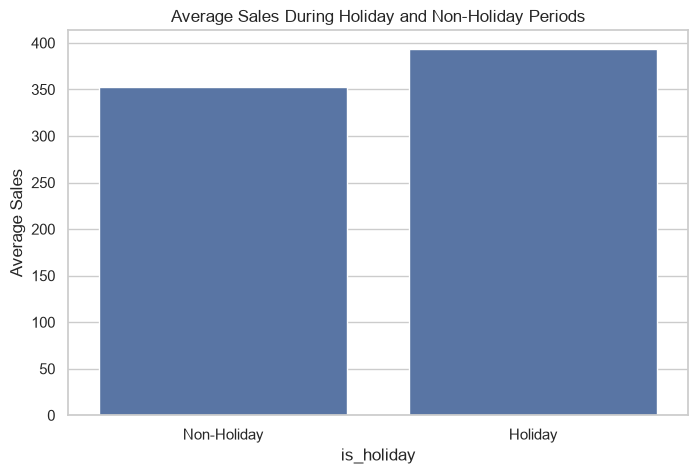

In [30]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=holiday_sales.index,
    y=holiday_sales.values
)

plt.xticks(
    [0, 1],
    ["Non-Holiday", "Holiday"]
)

plt.title("Average Sales During Holiday and Non-Holiday Periods")

plt.ylabel("Average Sales")

plt.show()

#### Seasonal demand analysis

### Monthly sales by product family

In [31]:
monthly_category = (
    train.groupby(["month", "family"])["sales"]
    .sum()
    .reset_index()
)

In [32]:
seasonal_pivot = monthly_category.pivot(
    index="month",
    columns="family",
    values="sales"
)

seasonal_pivot.head()

family,AUTOMOTIVE,BABY CARE,BEAUTY,BEVERAGES,BOOKS,BREAD/BAKERY,CELEBRATION,CLEANING,DAIRY,DELI,...,MAGAZINES,MEATS,PERSONAL CARE,PET SUPPLIES,PLAYERS AND ELECTRONICS,POULTRY,PREPARED FOODS,PRODUCE,SCHOOL AND OFFICE SUPPLIES,SEAFOOD
month,,,,,,,,,,,,,,,,,,,,,
1,47404.0,799.0,29604.0,19671443.0,774.0,3.743903e+06,64100.0,8934852.0,5723268.0,2.137782e+06,...,19665.0,2.772594e+06,2339644.0,30360.0,50774.0,2.898400e+06,816022.494072,1.129266e+07,7844.0,189047.995942
2,48098.0,859.0,26522.0,15413836.0,549.0,3.364322e+06,42575.0,8080157.0,5163833.0,1.965494e+06,...,20915.0,2.549628e+06,1999672.0,21563.0,30388.0,2.647820e+06,748878.677038,7.170824e+06,4604.0,169973.556104
3,54156.0,956.0,27500.0,19673616.0,472.0,3.867917e+06,68212.0,8917682.0,6075496.0,2.205450e+06,...,22251.0,2.787881e+06,2222838.0,32131.0,49103.0,2.883235e+06,843032.494951,1.116262e+07,13699.0,205090.710573
4,49758.0,663.0,27329.0,17787364.0,258.0,3.674524e+06,45621.0,8707337.0,5828380.0,2.139391e+06,...,24784.0,2.688575e+06,2316174.0,25629.0,38429.0,2.722753e+06,774452.186742,7.399004e+06,37639.0,181775.457243
5,50095.0,734.0,29717.0,18475757.0,152.0,3.998666e+06,45377.0,9118551.0,6129141.0,2.283716e+06,...,24753.0,2.893981e+06,2285668.0,26373.0,36084.0,2.887778e+06,775170.230078,7.980131e+06,20085.0,195548.157013


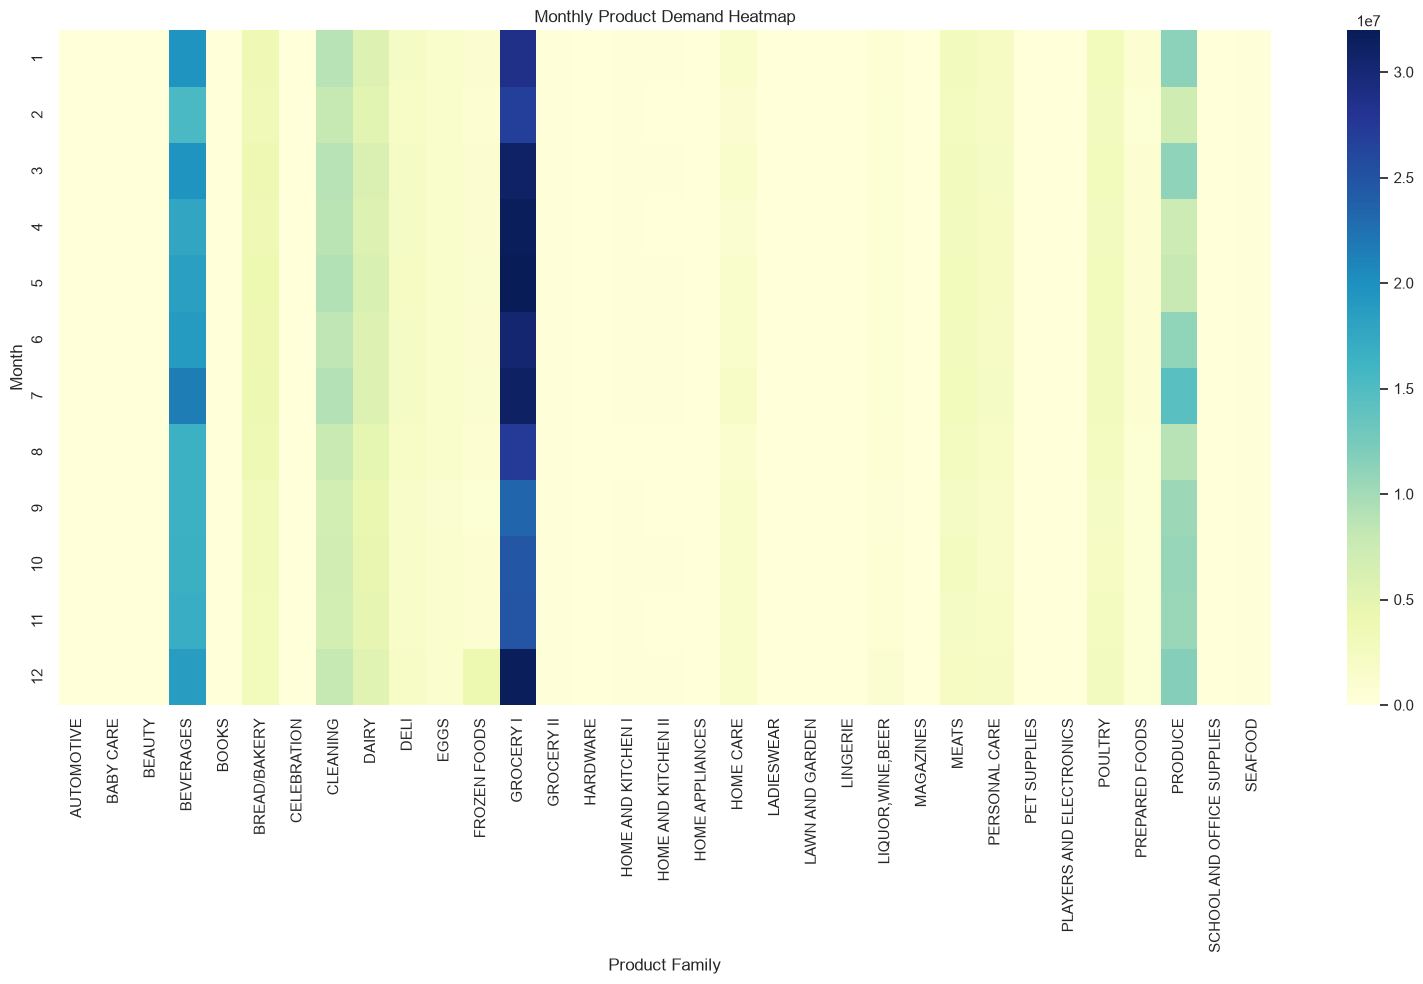

In [33]:
plt.figure(figsize=(16, 10))

sns.heatmap(
    seasonal_pivot,
    cmap="YlGnBu"
)

plt.title("Monthly Product Demand Heatmap")

plt.xlabel("Product Family")

plt.ylabel("Month")

plt.tight_layout()

plt.show()

#### Demand volatility analysis

### Calculate product demand variability

In [34]:
demand_volatility = (
    train.groupby("family")["sales"]
    .agg(
        average_demand="mean",
        demand_std="std",
        minimum_demand="min",
        maximum_demand="max"
    )
)

demand_volatility["CV"] = (
    demand_volatility["demand_std"] /
    demand_volatility["average_demand"].replace(0, np.nan)
)

demand_volatility.sort_values(
    by="CV",
    ascending=False
).head(15)

,average_demand,demand_std,minimum_demand,maximum_demand,CV
family,,,,,
BOOKS,0.070797,0.547981,0.0,51.000,7.740162
SCHOOL AND OFFICE SUPPLIES,2.961599,21.745937,0.0,1332.000,7.342633
BABY CARE,0.110528,0.681064,0.0,116.000,6.161901
HOME APPLIANCES,0.457476,0.969551,0.0,15.000,2.119350
FROZEN FOODS,154.766954,324.971305,0.0,14541.550,2.099746
MAGAZINES,2.929082,6.008492,0.0,79.000,2.051323
LAWN AND GARDEN,6.035475,12.283458,0.0,712.000,2.035210
PET SUPPLIES,3.921263,7.657852,0.0,106.000,1.952904
LADIESWEAR,7.160629,13.946302,0.0,147.000,1.947636


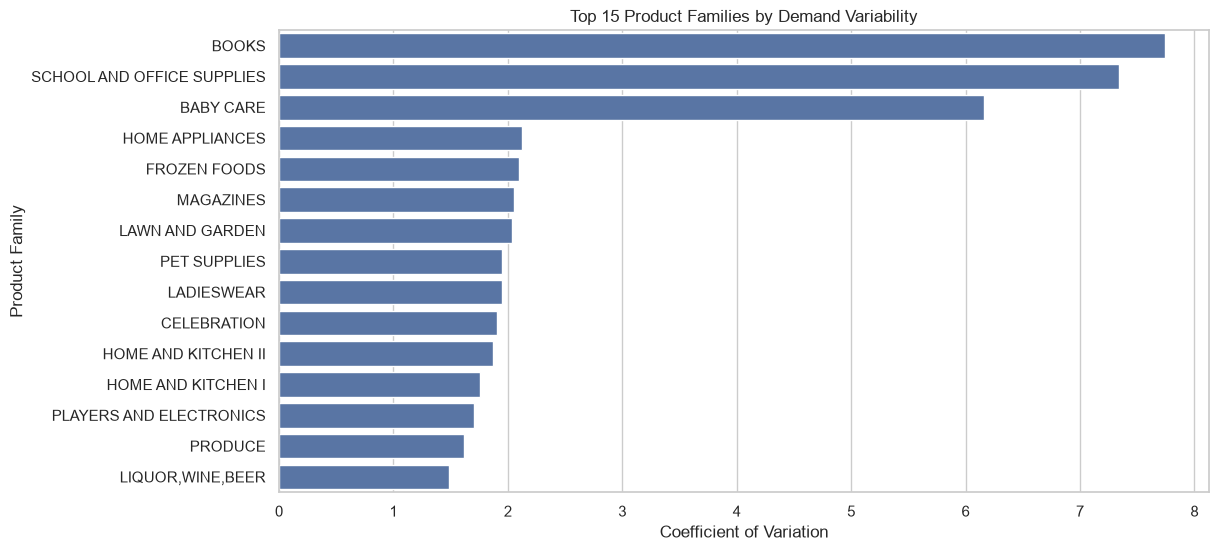

In [35]:
plt.figure(figsize=(12, 6))

volatility = demand_volatility.sort_values(
    "CV",
    ascending=False
).head(15)

sns.barplot(
    x=volatility["CV"],
    y=volatility.index
)

plt.title("Top 15 Product Families by Demand Variability")

plt.xlabel("Coefficient of Variation")

plt.ylabel("Product Family")

plt.show()

In [36]:
daily_sales = daily_sales.sort_values("date").copy()

daily_sales["MA_7"] = (
    daily_sales["sales"]
    .rolling(window=7)
    .mean()
)

daily_sales["MA_30"] = (
    daily_sales["sales"]
    .rolling(window=30)
    .mean()
)

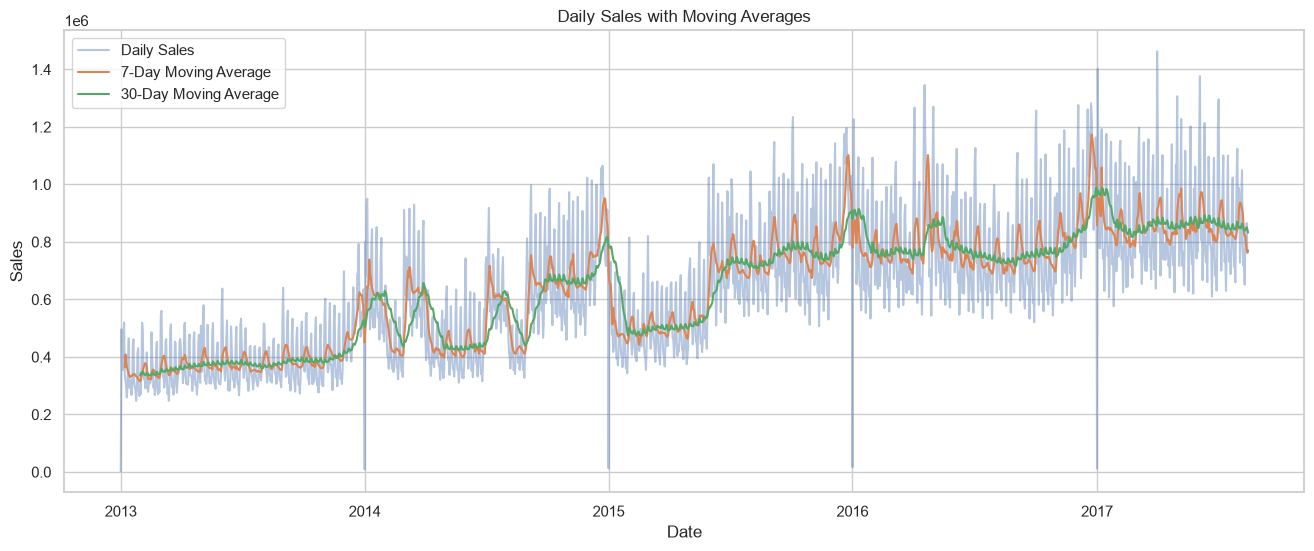

In [37]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_sales["date"],
    daily_sales["sales"],
    label="Daily Sales",
    alpha=0.4
)

plt.plot(
    daily_sales["date"],
    daily_sales["MA_7"],
    label="7-Day Moving Average"
)

plt.plot(
    daily_sales["date"],
    daily_sales["MA_30"],
    label="30-Day Moving Average"
)

plt.title("Daily Sales with Moving Averages")

plt.xlabel("Date")

plt.ylabel("Sales")

plt.legend()

plt.show()

In [38]:
correlation_data = train.merge(
    oil,
    on="date",
    how="left"
)

correlation_data = correlation_data.merge(
    transactions,
    on=["date", "store_nbr"],
    how="left"
)

correlation_data.rename(
    columns={
        "dcoilwtico": "oil_price",
        "transactions": "store_transactions"
    },
    inplace=True
)

correlation_data.head()

,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week,week,quarter,is_weekend,promotion_status,oil_price,store_transactions
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1,Tuesday,1,1,0,No Promotion,NaN,NaN
1,1,2013-01-01,1,BABY CARE,0.0,0,2013,1,1,Tuesday,1,1,0,No Promotion,NaN,NaN
2,2,2013-01-01,1,BEAUTY,0.0,0,2013,1,1,Tuesday,1,1,0,No Promotion,NaN,NaN
3,3,2013-01-01,1,BEVERAGES,0.0,0,2013,1,1,Tuesday,1,1,0,No Promotion,NaN,NaN
4,4,2013-01-01,1,BOOKS,0.0,0,2013,1,1,Tuesday,1,1,0,No Promotion,NaN,NaN


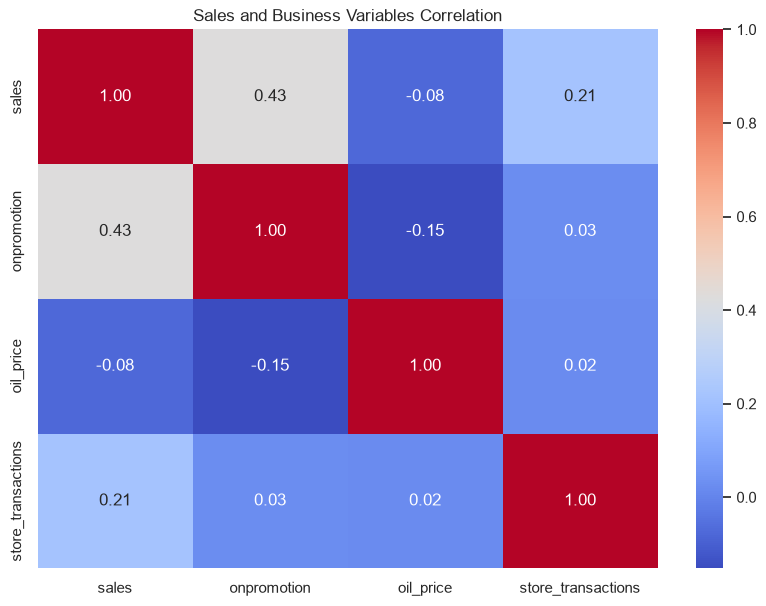

In [39]:
numeric_columns = [
    "sales",
    "onpromotion",
    "oil_price",
    "store_transactions"
]

correlation_matrix = (
    correlation_data[numeric_columns]
    .corr()
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Sales and Business Variables Correlation")

plt.show()

In [40]:
top_product = product_sales.index[0]

top_store = store_sales.index[0]

highest_weekday = weekday_sales.idxmax()

highest_month = monthly_sales.idxmax()

highest_month_number = highest_month.month

highest_volatility = (
    demand_volatility["CV"].idxmax()
)

print("========== BUSINESS INSIGHTS ==========")

print("Top Product Family:", top_product)

print("Top Store:", top_store)

print("Highest Demand Weekday:", highest_weekday)

print("Highest Sales Month:", highest_month_number)

print("Highest Demand Variability:", highest_volatility)

print("=======================================")

========== BUSINESS INSIGHTS ==========
Top Product Family: GROCERY I
Top Store: 44
Highest Demand Weekday: Sunday
Highest Sales Month: 12
Highest Demand Variability: BOOKS


In [41]:
product_sales.to_csv(
    "../reports/product_sales_analysis.csv"
)

store_sales.to_csv(
    "../reports/store_sales_analysis.csv"
)

monthly_sales.to_csv(
    "../reports/monthly_sales_analysis.csv"
)

demand_volatility.to_csv(
    "../reports/demand_volatility_analysis.csv"
)

print("EDA reports exported successfully!")

EDA reports exported successfully!
